In [108]:
import pandas as pd
import numpy as np


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [81]:
# data import

data = pd.read_csv("Desktop/Data Science training/Data sets/IBM Telco Customer churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Data Cleaning and Preparation

In [82]:
#Explore through the data

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [83]:
# Correct the data types on Charges column

data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors = 'coerce')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [84]:
# Get rid of the null values


data = data.dropna()
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

# STEP 1
### Define Your Features and target first, then split data before encoding
- For data where categories have more than two levels, an advanced level of encoding is required
- Encoding is done separately for Train and Test data after splitting

In [85]:
# Define X and y as Features and Target first

X = data.drop(["Churn", "customerID"], axis=1) # axis =1 tells pandas that we are dropping columns
y = data["Churn"]

X.head()
y.head()


0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object

In [86]:
# Encode the target variable using the mapping before splitting


y = y.map({"No": 0, "Yes": 1})
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [87]:
# Split the data into Train and Test data first with original columns

X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.2,
    random_state=66,
    stratify=y
) # we apply stratification for imbalanced datasets



# STEP 2
## Encoding Categorical variables for both Train and Test Data
- Begin by identifying the categorigal columns first

In [88]:
# Select all categorical columns and examine all the categories under

categories = data.select_dtypes(include='object').columns #selescting categorical columns


for col in categories:
    print(f"\n{col}:")
    print(data[col].unique()) # display all categories for each object column


customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Churn:
['No' 'Yes']


### In the train data, separate Categorical features from numerical features, and encode before recombining them

In [89]:
# First, identify all the categorical features and seperate them from numerical features

categorical_features = X_train.select_dtypes(include="object").columns

print(categorical_features)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [90]:
# second, identify all the numerical columns since at the end we will need to combine them

numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns

print(numerical_features)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


In [91]:
# now create an encoder using OneHotEncoding and fit it on the X_train features first then on the X_train

encoder = OneHotEncoder(handle_unknown="ignore",drop="first")


X_train_encoded = encoder.fit_transform(X_train[categorical_features]) # fit the encorder on the X_train

X_test_encoded = encoder.transform(X_test[categorical_features])# use the fitten encoder to transform X_test

# Here, all the preporecessing happens in the training section
# On the test data, we only apply what has been preprocessed in the training data


# And later, when a new customer enters the Streamlit app, we'll use that same fitted encoder.


# Prepare numerical features too

X_train_numerical = X_train[numerical_features]
X_test_numerical = X_test[numerical_features]

# scale numerical features
scaler = StandardScaler()

X_train_numerical_scaled = scaler.fit_transform(X_train_numerical) #fit scaler on train numerics

X_test_numerical_scaled = scaler.transform(X_test_numerical)# use the fitted scaler to transform X data

## STEP 3
### Convert the encoded features into proper dataframes and combine them with the numerical features


In [92]:
# Convert X_encoded into DataFrames since they are just a series

X_train_encoded = pd.DataFrame(
    X_train_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded.toarray(),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)


# also convert scaled numerics back to dataframes 

X_train_numerical_scaled = pd.DataFrame(
    X_train_numerical_scaled,
    columns=numerical_columns,
    index=X_train.index
)

X_test_numerical_scaled = pd.DataFrame(
    X_test_numerical_scaled,
    columns=numerical_columns,
    index=X_test.index
)

In [93]:
# Now combine the dataframes with the numeric features

X_train_final = pd.concat([X_train_numerical_scaled, X_train_encoded], axis=1) # concat combines the two dataframes to one

X_test_final = pd.concat([X_test_numerical_scaled, X_test_encoded],axis=1)

# we now have
#X_train_final
#X_test_final
#y_train
#y_test

## STEP 4 Fit the Logistic Reg Model

In [99]:
# fit the logistic model on the training data

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_final, y_train) # this is the learning stage of the model

# predict X_ test using trained model
y_pred = log_model.predict(X_test_final)

# Make an evaluation based on the y_test

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.66      0.54      0.59       374

    accuracy                           0.80      1407
   macro avg       0.75      0.72      0.73      1407
weighted avg       0.80      0.80      0.80      1407



In [105]:
# Evaluate using a confusion matrix

cm = confusion_matrix(y_test, y_pred)
cm

# confusion matrix brings about a 2 by 2 matrix
#[[TN  FP]
# [FN  TP]]

#TN = correctly predicted retained customers
#FP = predicted churn, but they stayed
#FN = predicted retained, but they actually churned
#TP = correctly predicted churn

array([[931, 102],
       [173, 201]])

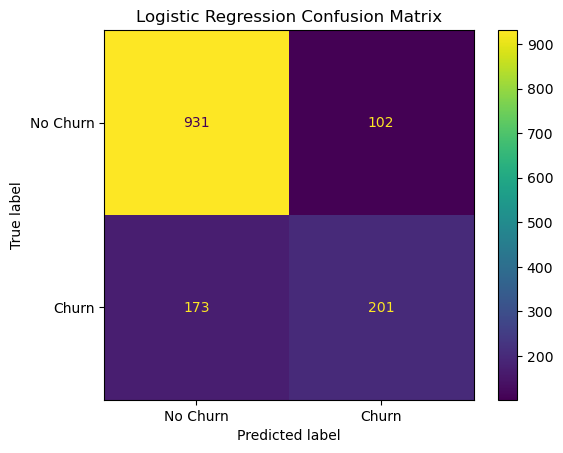

In [107]:
# Plot a confusion matrix to display what is observed


import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

## STEP 5 Fit a Random forest Classifier Model

In [110]:
# fit the random classifier

rf_model = RandomForestClassifier(n_estimators=100,random_state=23)
rf_model.fit(X_train_final, y_train)

# use the trained model to predict x test
y_predicted = rf_model.predict(X_test_final)

#Make an evaluation

print(classification_report(y_test, y_predicted))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.71      1407
weighted avg       0.77      0.79      0.78      1407

